# LOB 101 — Analyse du Limit Order Book
**Données** : TOTF (Total SA) — Euronext Paris, 2014

Plan :
- **Etape 1** — Imports et chargement
- **Etape 2** — Comprendre le book : types d'ordres
- **Etape 3** — Variables de la slide 6 (Δt, r, flux) — version optimisée, 126 jours

---
## Etape 1 — Imports et chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

DATA_PATH  = '../Data MDS/'
TRADE_FILE = DATA_PATH + 'TOTF_trade_2014_2017.csv.gz'
BOOK_FILE  = DATA_PATH + 'TOTF_book_2014-04-13_to_2014-10-12.csv.gz'
TICK = 0.005

bid_q_cols = [f'bidQ_{i}' for i in range(1, 6)]
ask_q_cols = [f'askQ_{i}' for i in range(1, 6)]

def market_hours(df):
    h = df['datetime'].dt.hour + df['datetime'].dt.minute / 60
    # On coupe a 15h25 pour eviter les donnees invalides de cloture
    # (bid=0 / ask=0 apres 15h30)
    return df[(h >= 9.5) & (h < 15.42)].copy().reset_index(drop=True)

# Lister tous les jours disponibles
all_dates = set()
for chunk in pd.read_csv(BOOK_FILE, usecols=['date'], chunksize=500_000):
    all_dates.update(chunk['date'].unique())
ALL_DAYS = sorted(all_dates)
print(f'{len(ALL_DAYS)} jours disponibles : {ALL_DAYS[0]} -> {ALL_DAYS[-1]}')

126 jours disponibles : 2014-04-14 -> 2014-10-10


---
## Etape 2 — Detecter le type d'ordre (sur 1 jour exemple)

**Cote BID :**
- `bidQ_1` augmente → **ordre limite** achat
- `bidQ_1` diminue + trade a ce prix → **ordre market** vente
- `bidQ_1` diminue + pas de trade → **annulation** achat

**Cote ASK :** logique symmetrique.

In [2]:
DAY = '2014-04-14'

trade_chunks = []
for chunk in pd.read_csv(TRADE_FILE, chunksize=200_000):
    sub = chunk[chunk['date'] == DAY]
    if len(sub): trade_chunks.append(sub)
    if chunk['date'].max() > DAY: break
df_trade_ex = pd.concat(trade_chunks, ignore_index=True)
df_trade_ex['datetime'] = pd.to_datetime(df_trade_ex['date'] + ' ' + df_trade_ex['time'])
df_trade_ex = market_hours(df_trade_ex)

book_chunks = []
for chunk in pd.read_csv(BOOK_FILE, chunksize=200_000):
    sub = chunk[chunk['date'] == DAY]
    if len(sub): book_chunks.append(sub)
    if chunk['date'].max() > DAY: break
df_book_ex = pd.concat(book_chunks, ignore_index=True)
df_book_ex['datetime'] = pd.to_datetime(df_book_ex['date'] + ' ' + df_book_ex['time'])
df_book_ex = market_hours(df_book_ex)

trades_agg = df_trade_ex.groupby(['time','trade.price'])['trade.volume'].sum().reset_index()
trade_prices_by_time = trades_agg.groupby('time')['trade.price'].apply(set).to_dict()

df = df_book_ex.copy()
df['dBidQ']    = df['bidQ_1'].diff()
df['dAskQ']    = df['askQ_1'].diff()
df['prev_bid'] = df['bid_1'].shift(1)
df['prev_ask'] = df['ask_1'].shift(1)

def had_trade_at(time, price):
    return any(abs(price - p) < 0.001 for p in trade_prices_by_time.get(time, set()))

def classify_event(row):
    if pd.isna(row['dBidQ']): return 'Initial snapshot'
    dB, dA, t = row['dBidQ'], row['dAskQ'], row['time']
    if dB > 0: return 'Limit order (buy)'
    if dB < 0: return 'Market order (sell)' if had_trade_at(t, row['prev_bid']) else 'Cancellation (buy)'
    if dA > 0: return 'Limit order (sell)'
    if dA < 0: return 'Market order (buy)'  if had_trade_at(t, row['prev_ask']) else 'Cancellation (sell)'
    return 'No change'

df['event_type'] = df.apply(classify_event, axis=1)
counts = df['event_type'].value_counts()
total  = len(df)
print(f'=== Distribution des types d ordre — {DAY} ===')
for evt, cnt in counts.items():
    print(f'  {evt:<25} : {cnt:>8,}  ({100*cnt/total:.1f}%)')

=== Distribution des types d ordre — 2014-04-14 ===
  No change                 :  373,398  (72.2%)
  Limit order (sell)        :   40,108  (7.8%)
  Limit order (buy)         :   34,362  (6.6%)
  Cancellation (sell)       :   27,508  (5.3%)
  Cancellation (buy)        :   23,490  (4.5%)
  Market order (buy)        :   10,372  (2.0%)
  Market order (sell)       :    7,642  (1.5%)
  Initial snapshot          :        1  (0.0%)


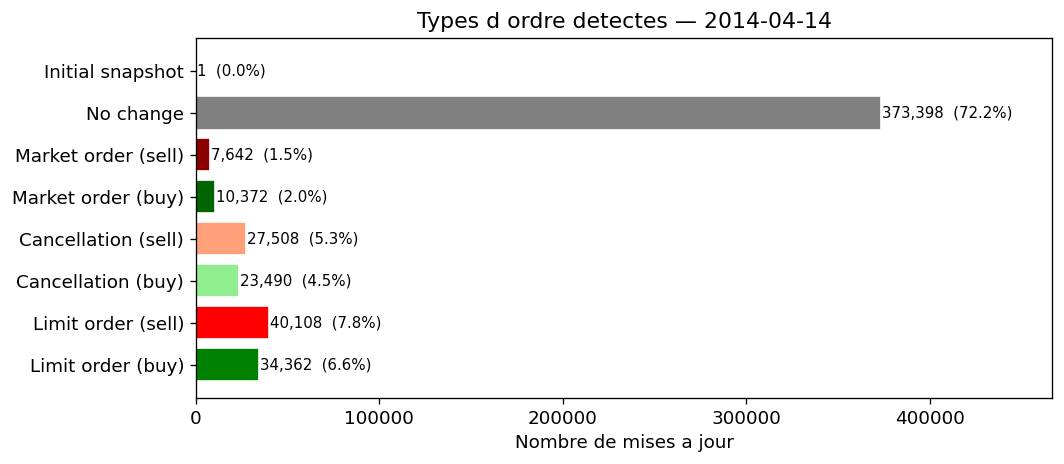

In [3]:
order  = ['Limit order (buy)','Limit order (sell)',
          'Cancellation (buy)','Cancellation (sell)',
          'Market order (buy)','Market order (sell)',
          'No change','Initial snapshot']
colors = ['green','red','lightgreen','lightsalmon','darkgreen','darkred','gray','lightgray']
vals   = [counts.get(o, 0) for o in order]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(order, vals, color=colors, edgecolor='white')
for bar, val in zip(bars, vals):
    ax.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
            f'{val:,}  ({100*val/total:.1f}%)', va='center', fontsize=9)
ax.set_xlabel('Nombre de mises a jour')
ax.set_title(f'Types d ordre detectes — {DAY}')
ax.set_xlim(0, max(vals) * 1.25)
plt.tight_layout()
plt.show()

---
## Step 3 — VAR

| Variable | Definition |
|---|---|
| **Δtₙ** | time between 2 significant price changes |
| **rₙ** | log-rendement of mid-price |
| **V^lo,b / V^lo,a** | volumes of limit orders bid / ask |
| **V^c,b / V^c,a** | volumes annulesof cancellations bid / ask |
| **V^ex,b / V^ex,a** | volumes of market orders bid / ask |

In [ ]:
def process_day(bk, tr):
    bk = bk.reset_index(drop=True)

    bk = bk[(bk['bid_1'] > 0) & (bk['ask_1'] > 0)].reset_index(drop=True)
    if len(bk) < 10:
        return pd.DataFrame()

    # --- 1. Significant price changes ---
    prev_bid = bk['bid_1'].shift(1)
    prev_ask = bk['ask_1'].shift(1)
    sig_mask = (
        (np.abs(bk['bid_1'] - prev_ask) < TICK) |
        (np.abs(bk['ask_1'] - prev_bid) < TICK)
    )
    sig_arr = np.where(sig_mask)[0]
    if len(sig_arr) < 2:
        return pd.DataFrame()

    # --- 2. Assignement of each line to its bloc ---
    block_ids = np.searchsorted(sig_arr, np.arange(len(bk)), side='right') - 1

    # --- 3. Flows ---
    diff_b = bk[bid_q_cols].diff().values
    diff_a = bk[ask_q_cols].diff().values
    diff_b[sig_arr] = 0
    diff_a[sig_arr] = 0
    #This latest point ensure that the consummering of a liquidity doesn't traduce in a volume variation

    Vlo_b = pd.Series(np.nansum(np.clip(diff_b, 0, None), axis=1)).groupby(block_ids).sum()
    Vlo_a = pd.Series(np.nansum(np.clip(diff_a, 0, None), axis=1)).groupby(block_ids).sum()
    Vc_b  = pd.Series(np.nansum(np.clip(diff_b, None, 0), axis=1)).abs().groupby(block_ids).sum()
    Vc_a  = pd.Series(np.nansum(np.clip(diff_a, None, 0), axis=1)).abs().groupby(block_ids).sum()

    # --- 4. Executions : Lee-Ready Law---
    tr = tr.sort_values('datetime').copy().reset_index(drop=True)
    tr['direction'] = np.sign(tr['trade.price'].diff()).replace(0, np.nan).ffill().fillna(1)
    sig_times = bk.loc[sig_arr, 'datetime'].values
    trade_blk = np.searchsorted(sig_times, tr['datetime'].values, side='right') - 1
    valid = (trade_blk >= 0) & (trade_blk < len(sig_arr) - 1)
    tb = trade_blk[valid]
    tv = tr.loc[valid, 'trade.volume'].values
    td = tr.loc[valid, 'direction'].values
    Vex_a = pd.Series(tv * (td ==  1)).groupby(tb).sum()
    Vex_b = pd.Series(tv * (td == -1)).groupby(tb).sum()

    # --- 5. Delta_t and r ---
    idx = np.arange(len(sig_arr) - 1)
    sig_times_dt = pd.to_datetime(sig_times)
    dt_arr = np.diff(sig_times_dt).astype('timedelta64[s]').astype(float)
    mid = (bk['bid_1'] + bk['ask_1']) / 2
    mid_sig = mid.iloc[sig_arr].values
    with np.errstate(divide='ignore', invalid='ignore'):
        r_arr = np.log(mid_sig[1:] / mid_sig[:-1])

    df_out = pd.DataFrame({
        't'      : bk.loc[sig_arr[1:], 'datetime'].values,
        'delta_t': dt_arr,
        'r'      : r_arr,
        'Vlo_b'  : Vlo_b.reindex(idx, fill_value=0).values,
        'Vlo_a'  : Vlo_a.reindex(idx, fill_value=0).values,
        'Vc_b'   : Vc_b.reindex(idx,  fill_value=0).values,
        'Vc_a'   : Vc_a.reindex(idx,  fill_value=0).values,
        'Vex_b'  : Vex_b.reindex(idx, fill_value=0).values,
        'Vex_a'  : Vex_a.reindex(idx, fill_value=0).values,
    })

    df_out = df_out[
        (df_out['delta_t'] > 0) &
        np.isfinite(df_out['r']) &
        (df_out['r'].abs() < 0.01)  
    ]
    return df_out

process_day() definie.


In [ ]:
import time

all_vars = []
t0 = time.time()

book_by_day  = {}
trade_by_day = {}

for chunk in pd.read_csv(BOOK_FILE, chunksize=300_000):
    chunk['datetime'] = pd.to_datetime(chunk['date'] + ' ' + chunk['time'])
    for day, grp in chunk.groupby('date'):
        if day not in book_by_day:
            book_by_day[day] = []
        book_by_day[day].append(grp)

for chunk in pd.read_csv(TRADE_FILE, chunksize=300_000):
    chunk['datetime'] = pd.to_datetime(chunk['date'] + ' ' + chunk['time'])
    for day, grp in chunk.groupby('date'):
        if day not in ALL_DAYS: continue
        if day not in trade_by_day:
            trade_by_day[day] = []
        trade_by_day[day].append(grp)

print(f'Loading ended in {time.time()-t0:.1f}s')
print(f'Days book : {len(book_by_day)} | Days trade : {len(trade_by_day)}')

t1 = time.time()
for day in ALL_DAYS:
    if day not in book_by_day or day not in trade_by_day:
        continue
    bk = market_hours(pd.concat(book_by_day[day],  ignore_index=True))
    tr = market_hours(pd.concat(trade_by_day[day], ignore_index=True))
    res = process_day(bk, tr)
    if len(res):
        all_vars.append(res)

df_vars = pd.concat(all_vars, ignore_index=True)
df_vars['t'] = pd.to_datetime(df_vars['t'])

print(f'Treating ended in{time.time()-t1:.1f}s')
print(f'Total observations : {len(df_vars):,} on {df_vars["t"].dt.date.nunique()} days')
print()
print(df_vars[['delta_t','r','Vlo_b','Vlo_a','Vc_b','Vc_a','Vex_b','Vex_a']].describe().round(2).to_string())

Chargement book...
Chargement trade...
Chargement termine en 72.3s
Jours book : 126 | Jours trade : 126

Traitement...
Traitement termine en 44.7s
Total observations : 147,544 sur 126 jours

         delta_t         r       Vlo_b       Vlo_a        Vc_b        Vc_a      Vex_b      Vex_a
count  147544.00  147544.0   147544.00   147544.00   147544.00   147544.00  147544.00  147544.00
mean       18.07      -0.0    31990.76    33596.77    31880.14    33488.70    1003.86    1019.33
std        66.01       0.0    84521.32    97124.03    84454.44    97115.44    3362.93    3451.38
min         1.00      -0.0        0.00        0.00        0.00        0.00       0.00       0.00
25%         1.00       0.0        0.00        0.00        0.00        0.00       0.00       0.00
50%         1.00       0.0      300.00      311.00      200.00      200.00       0.00       0.00
75%        11.00       0.0    32661.25    33286.75    32485.25    33119.00     827.00     813.00
max      3729.00       0.0  41071

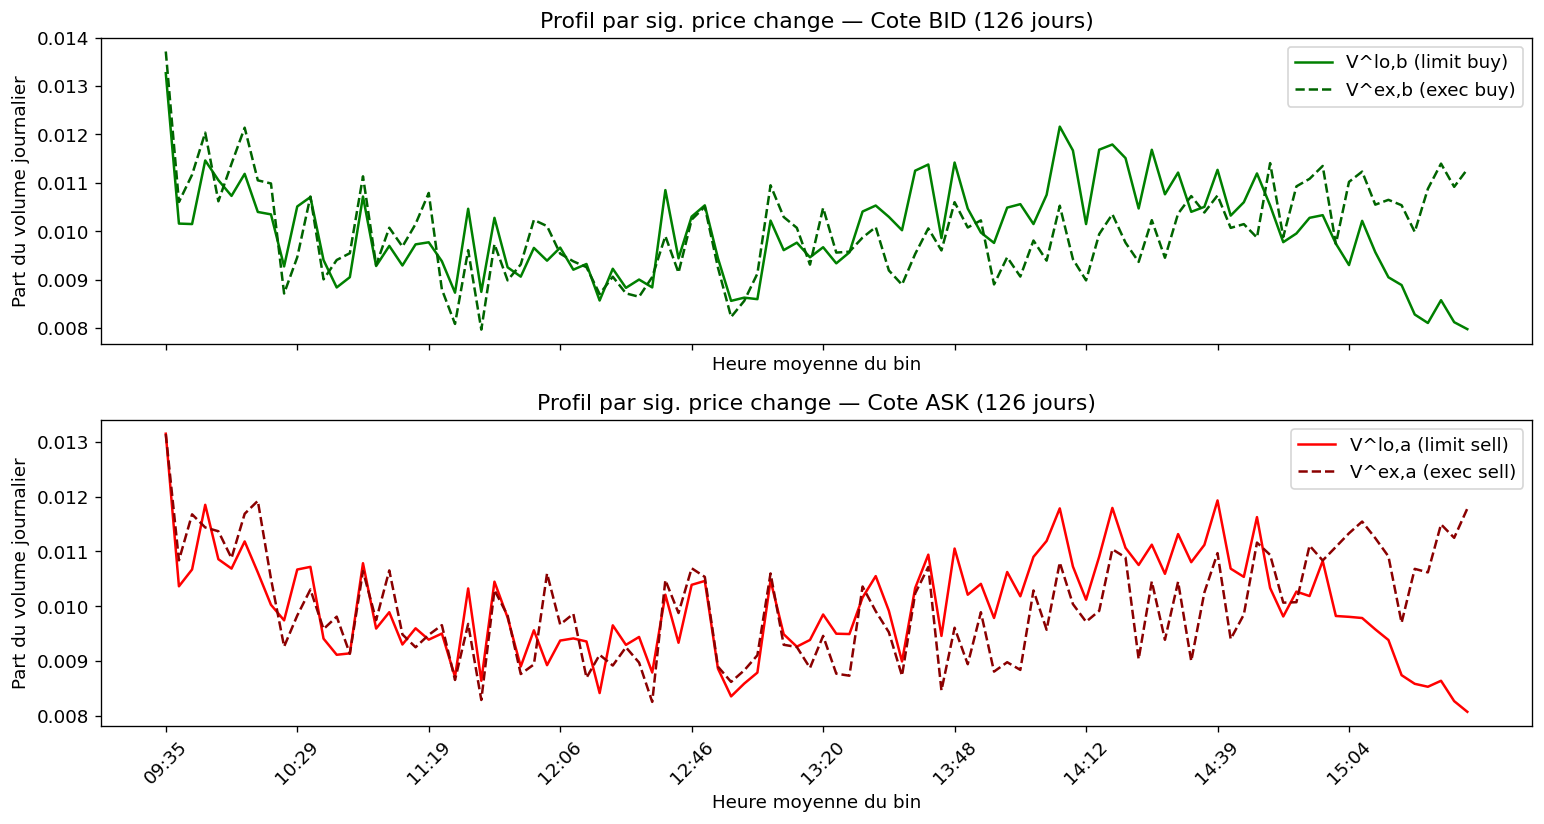

In [ ]:
# ================================================================
# Profil par indice de changement de prix significatif
# avec labels temporels sur l axe X
# ================================================================

df_vars['date'] = df_vars['t'].dt.date

# Winsorisation au 99e percentile
for col in ['Vlo_b','Vlo_a','Vex_b','Vex_a','Vc_b','Vc_a']:
    cap = df_vars[col].quantile(0.99)
    df_vars[col+'_w'] = df_vars[col].clip(upper=cap)

N_BINS = 100

all_profiles = []
bin_times    = []   # pour stocker l heure mediane de chaque bin

for day, grp in df_vars.groupby('date'):
    grp = grp.reset_index(drop=True)
    N = len(grp)
    if N < N_BINS: 
        continue

    grp['pos'] = np.arange(N) / N
    grp['bin'] = (grp['pos'] * N_BINS).astype(int).clip(upper=N_BINS-1)

    # Flux par bin
    day_profile = grp.groupby('bin')[
        ['Vlo_b_w','Vlo_a_w','Vex_b_w','Vex_a_w','Vc_b_w','Vc_a_w']
    ].sum()
    day_profile = day_profile / day_profile.sum()
    all_profiles.append(day_profile)

    # Heure mediane de chaque bin (en minutes depuis minuit)
    grp['minutes'] = grp['t'].dt.hour * 60 + grp['t'].dt.minute + grp['t'].dt.second / 60
    bin_times.append(grp.groupby('bin')['minutes'].median())

# Moyenne des profils et des heures par bin
profile   = pd.concat(all_profiles).groupby(level=0).mean()
avg_times = pd.concat(bin_times).groupby(level=0).mean()  # minutes depuis minuit

# Convertir en labels HH:MM
def min_to_hhmm(m):
    h = int(m) // 60
    mn = int(m) % 60
    return f'{h:02d}:{mn:02d}'

time_labels = [min_to_hhmm(avg_times[b]) for b in profile.index]

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

x = profile.index

ax = axes[0]
ax.plot(x, profile['Vlo_b_w'], color='green',    linewidth=1.5, label='V^lo,b (limit buy)')
ax.plot(x, profile['Vex_b_w'], color='darkgreen', linewidth=1.5, label='V^ex,b (exec buy)', linestyle='--')
ax.set_ylabel('Part du volume journalier')
ax.set_title('Profil par sig. price change — Cote BID (126 jours)')
ax.legend()

ax2 = axes[1]
ax2.plot(x, profile['Vlo_a_w'], color='red',    linewidth=1.5, label='V^lo,a (limit sell)')
ax2.plot(x, profile['Vex_a_w'], color='darkred', linewidth=1.5, label='V^ex,a (exec sell)', linestyle='--')
ax2.set_ylabel('Part du volume journalier')
ax2.set_title('Profil par sig. price change — Cote ASK (126 jours)')
ax2.legend()

# Labels temporels sur l axe X
step = max(1, N_BINS // 10)
for ax in axes:
    ax.set_xticks(x[::step])
    ax.set_xticklabels(time_labels[::step], rotation=45)
    ax.set_xlabel('Heure moyenne du bin')

plt.tight_layout()
plt.show()

---
## Etape 4 — Visualisation des séries sur les 126 jours

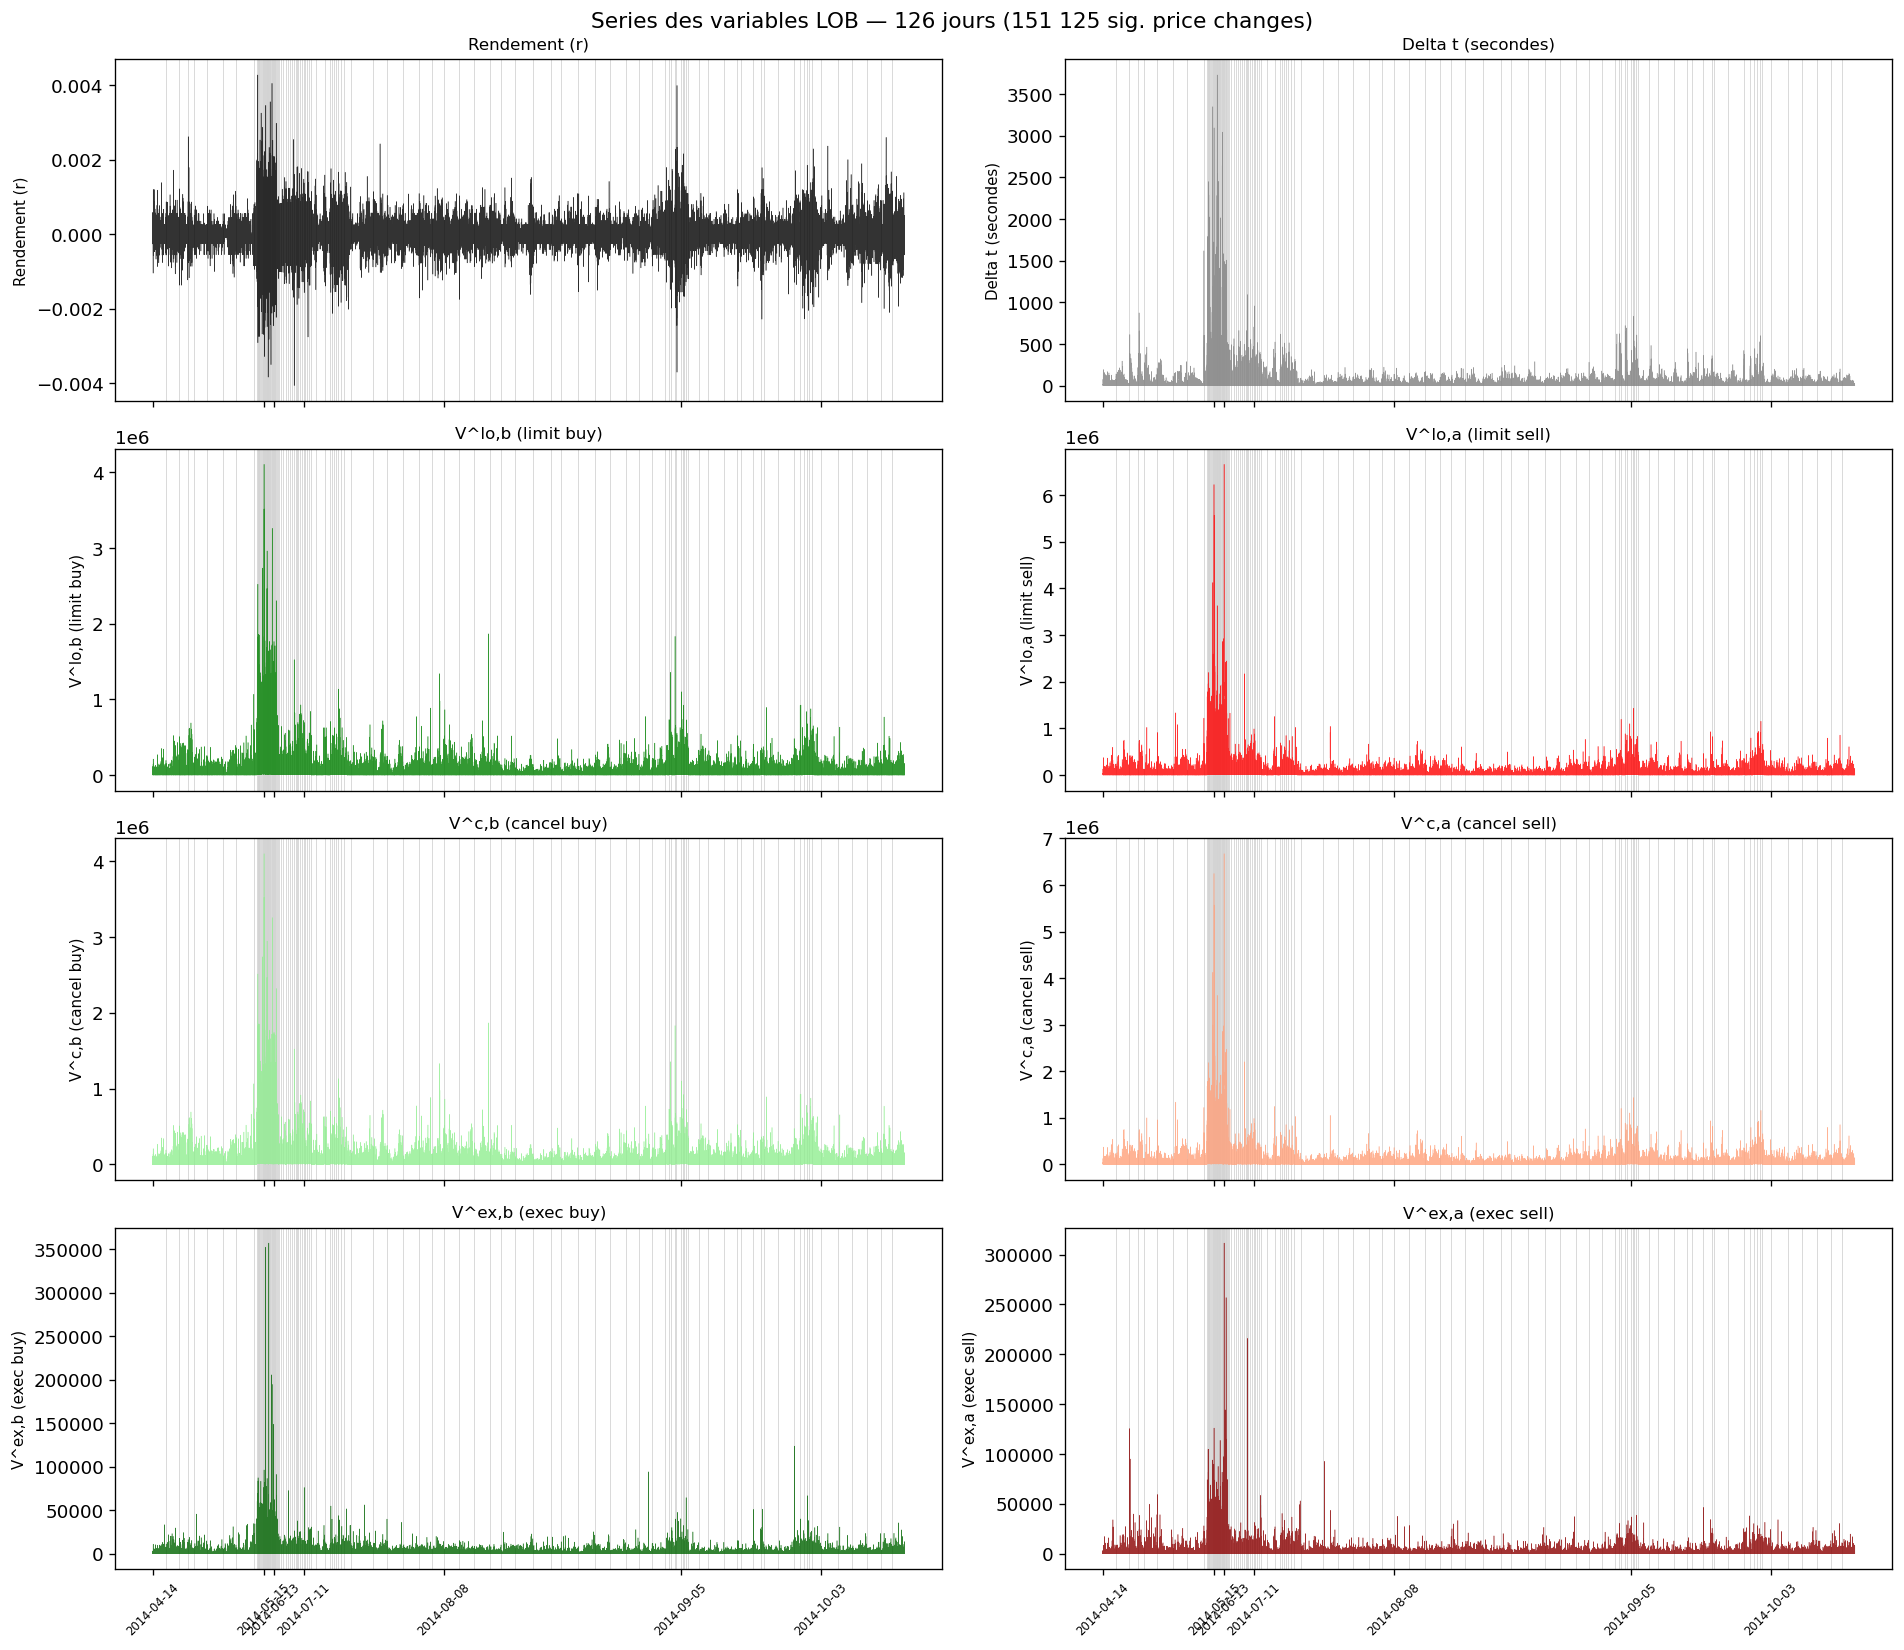

In [7]:
# Serie complete sur les 126 jours — toutes les variables
# On trace chaque variable en fonction de l indice n (sig. price change)
# Les barres grises verticales marquent les frontieres entre jours

fig, axes = plt.subplots(4, 2, figsize=(16, 14), sharex=True)
fig.suptitle('Series des variables LOB — 126 jours (151 125 sig. price changes)', fontsize=13)

variables = [
    ('r',     'Rendement (r)',         'black'),
    ('delta_t','Delta t (secondes)',    'gray'),
    ('Vlo_b', 'V^lo,b (limit buy)',    'green'),
    ('Vlo_a', 'V^lo,a (limit sell)',   'red'),
    ('Vc_b',  'V^c,b (cancel buy)',    'lightgreen'),
    ('Vc_a',  'V^c,a (cancel sell)',   'lightsalmon'),
    ('Vex_b', 'V^ex,b (exec buy)',     'darkgreen'),
    ('Vex_a', 'V^ex,a (exec sell)',    'darkred'),
]

# Indices de debut de chaque nouveau jour (pour tracer les separateurs)
day_starts = df_vars.groupby('date').apply(lambda x: x.index[0]).values

x = np.arange(len(df_vars))

for ax, (col, label, color) in zip(axes.flat, variables):
    ax.plot(x, df_vars[col].values, color=color, linewidth=0.3, alpha=0.8)

    # Barres grises aux frontieres de jours
    for ds in day_starts[1:]:
        ax.axvline(ds, color='lightgray', linewidth=0.5, zorder=0)

    ax.set_ylabel(label, fontsize=9)
    ax.set_title(label, fontsize=10)

    # Quelques ticks X avec les dates
    tick_positions = day_starts[::20]
    tick_labels    = [str(df_vars.loc[p, 'date']) for p in tick_positions]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=45, fontsize=7)

plt.tight_layout()
plt.show()

### Etape 4b — Normalisation par le profil intraday

Pour chaque observation $n$, on calcule son bin de position dans la journée (0-99),
puis on divise par le flux moyen de ce bin sur les 126 jours :

$$\tilde{V}_n = \frac{V_n}{\lambda_V(\text{bin}_n)}$$

Les séries normalisées `*_norm` sont ensuite utilisées pour le VAR.

In [ ]:
flux_cols = ['Vlo_b', 'Vlo_a', 'Vc_b', 'Vc_a', 'Vex_b', 'Vex_a']

# --- 1. Calculer le bin de position pour chaque observation ---
# (meme logique que dans l etape du profil intraday)
df_vars['date'] = df_vars['t'].dt.date

df_vars['bin'] = df_vars.groupby('date').cumcount()
day_sizes = df_vars.groupby('date')['bin'].transform('count')
df_vars['bin'] = ((df_vars['bin'] / day_sizes) * N_BINS).astype(int).clip(upper=N_BINS - 1)

# --- 2. Profil moyen par bin sur les 126 jours ---
# On recalcule directement depuis df_vars (plus simple que d utiliser all_profiles)
# lambda_V(bin) = moyenne de V dans ce bin sur tous les jours
lambda_profile = df_vars.groupby('bin')[flux_cols].mean()

print('Profil intraday moyen par bin (premieres lignes) :')
print(lambda_profile.head(10).round(1))

# --- 3. Normalisation ---
# Pour chaque observation : V_tilde = V / lambda(bin)
# On remplace les lambda = 0 par NaN pour eviter les divisions par zero
for col in flux_cols:
    lam = df_vars['bin'].map(lambda_profile[col])
    lam = lam.replace(0, np.nan)
    df_vars[col + '_norm'] = df_vars[col] / lam

# r et delta_t ne dependent pas de l heure de la meme facon
# on les garde tels quels (deja stationnaires)
df_vars['r_norm']       = df_vars['r']
df_vars['delta_t_norm'] = df_vars['delta_t']

norm_cols = ['r_norm', 'delta_t_norm',
             'Vlo_b_norm', 'Vlo_a_norm',
             'Vc_b_norm',  'Vc_a_norm',
             'Vex_b_norm', 'Vex_a_norm']

print()
print('Stats apres normalisation :')
print(df_vars[norm_cols].describe().round(3))

### Etape 4c — Transformation Box-Cox

Après normalisation intraday, les flux sont encore asymétriques (beaucoup de zéros, queue épaisse à droite). La Box-Cox rend les distributions plus gaussiennes :

$$V^{(\lambda)} = \begin{cases} \frac{V^\lambda - 1}{\lambda} & \text{si } \lambda \neq 0 \\ \ln(V) & \text{si } \lambda = 0 \end{cases}$$

Le paramètre $\lambda$ est estimé par maximum de vraisemblance pour chaque variable. On l'applique sur les valeurs **strictement positives** (on ignore les zéros).

Parametres lambda Box-Cox estimes :
  delta_t            -> log (lambda=0 impose)
  Vlo_b_norm         -> lambda = -0.016
  Vlo_a_norm         -> lambda = -0.052
  Vc_b_norm          -> lambda = -0.043
  Vc_a_norm          -> lambda = -0.032
  Vex_b_norm         -> lambda = -0.117
  Vex_a_norm         -> lambda = -0.105

Distribution apres Box-Cox :
        r_norm_bc  delta_t_norm_bc  Vlo_b_norm_bc  Vlo_a_norm_bc  \
count  151125.000       151125.000     151125.000     151125.000   
mean        0.000            1.248         -6.035         -4.326   
std         0.008            1.588          6.070          4.333   
min        -0.004            0.000        -12.052         -8.572   
25%         0.000            0.000        -12.052         -8.572   
50%         0.000            0.000         -4.852         -5.219   
75%         0.000            2.398          0.024         -0.008   
max         0.820            8.224          4.690          4.516   

       Vc_b_norm_bc  Vc_a_norm_bc  

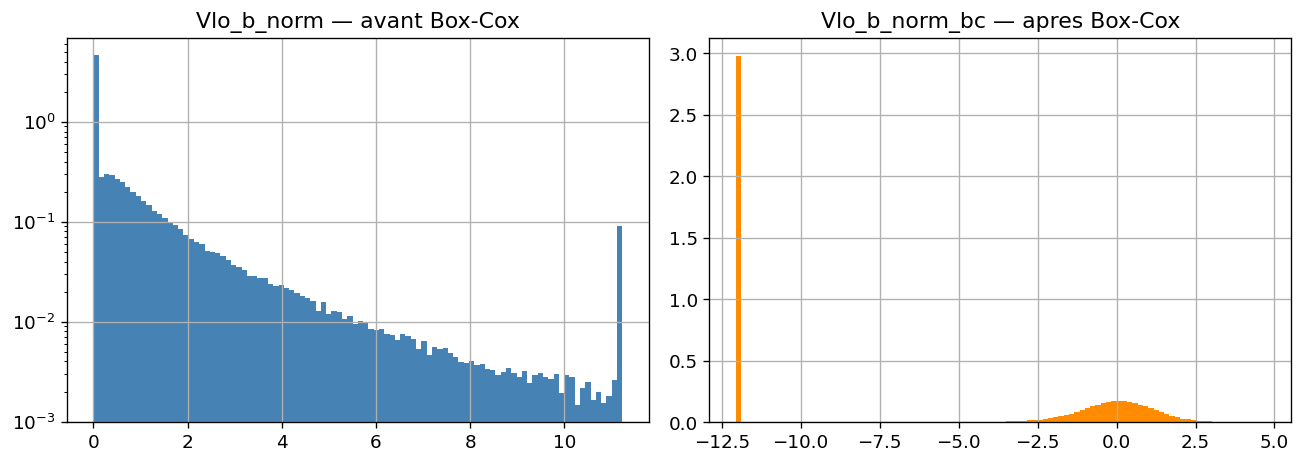

In [37]:
from scipy.stats import boxcox

# Box-Cox sur les flux normalises (strictement positifs)
# r et delta_t : on garde r tel quel, log(delta_t) suffit
bc_cols = ['Vlo_b_norm', 'Vlo_a_norm', 'Vc_b_norm', 'Vc_a_norm', 'Vex_b_norm', 'Vex_a_norm']

lambdas = {}

for col in bc_cols:
    serie = df_vars[col].dropna()
    # Box-Cox necessite des valeurs > 0 strictement
    # On remplace les 0 par la moitie du minimum non-nul
    min_pos = serie[serie > 0].min()
    serie_pos = serie.clip(lower=min_pos / 2)

    # Estimation du lambda optimal
    _, lam = boxcox(serie_pos.dropna())
    lambdas[col] = lam

    # Application a tout df_vars
    s = df_vars[col].clip(lower=min_pos / 2)
    if abs(lam) < 0.01:   # lambda ≈ 0 → log
        df_vars[col + '_bc'] = np.log(s)
    else:
        df_vars[col + '_bc'] = (s ** lam - 1) / lam

# r : on garde tel quel (deja symetrique autour de 0)
df_vars['r_norm_bc']       = df_vars['r_norm']
# delta_t : log-transformation (durees toujours positives)
df_vars['delta_t_norm_bc'] = np.log(df_vars['delta_t_norm'].clip(lower=0.01))

bc_norm_cols = ['r_norm_bc', 'delta_t_norm_bc',
                'Vlo_b_norm_bc', 'Vlo_a_norm_bc',
                'Vc_b_norm_bc',  'Vc_a_norm_bc',
                'Vex_b_norm_bc', 'Vex_a_norm_bc']

print('Parametres lambda Box-Cox estimes :')
print(f'  {"delta_t":<18} -> log (lambda=0 impose)')
for col, lam in lambdas.items():
    print(f'  {col:<18} -> lambda = {lam:.3f}')

print()
print('Distribution apres Box-Cox :')
print(df_vars[bc_norm_cols].describe().round(3))

# Visualisation avant / apres Box-Cox sur Vlo_b
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_vars['Vlo_b_norm'].clip(upper=df_vars['Vlo_b_norm'].quantile(0.99)).hist(
    bins=100, ax=axes[0], color='steelblue', density=True)
axes[0].set_title('Vlo_b_norm — avant Box-Cox')
axes[0].set_yscale('log')

df_vars['Vlo_b_norm_bc'].hist(bins=100, ax=axes[1], color='darkorange', density=True)
axes[1].set_title('Vlo_b_norm_bc — apres Box-Cox')

plt.tight_layout()
plt.show()

### Etape 4d — Standardisation (mean=0, std=1)

Après Box-Cox, les variables ont des échelles très différentes ce qui peut déstabiliser la matrice compagnon du VAR. On centre et réduit chaque série :

$$\hat{V}_n = \frac{\tilde{V}_n^{(\lambda)} - \mu_V}{\sigma_V}$$

où $\mu_V$ et $\sigma_V$ sont la moyenne et l'écart-type estimés sur l'échantillon d'entraînement.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardisation sur toutes les series Box-Cox
scaler = StandardScaler()

# On fitte le scaler sur les donnees disponibles
data_bc = df_vars[bc_norm_cols].dropna()
scaler.fit(data_bc)

# Noms des colonnes standardisees
std_cols = [c + '_std' for c in bc_norm_cols]

# Application
df_vars_std = df_vars.copy()
df_vars_std[std_cols] = np.nan
mask_valid = df_vars[bc_norm_cols].notna().all(axis=1)
df_vars_std.loc[mask_valid, std_cols] = scaler.transform(df_vars.loc[mask_valid, bc_norm_cols])

print('Moyennes apres standardisation (doit etre ~0) :')
print(df_vars_std[std_cols].mean().round(4))
print()
print('Ecarts-types apres standardisation (doit etre ~1) :')
print(df_vars_std[std_cols].std().round(4))
print()

# Verification visuelle : distribution de Vlo_b a chaque etape
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

df_vars['Vlo_b'].clip(upper=df_vars['Vlo_b'].quantile(0.99)).hist(
    bins=80, ax=axes[0], color='steelblue', density=True)
axes[0].set_title('1. Brut')
axes[0].set_yscale('log')

df_vars['Vlo_b_norm_bc'].hist(bins=80, ax=axes[1], color='darkorange', density=True)
axes[1].set_title('2. Normalise + Box-Cox')

df_vars_std['Vlo_b_norm_bc_std'].dropna().hist(bins=80, ax=axes[2], color='green', density=True)
axes[2].set_title('3. Standardise (mean=0, std=1)')

fig.suptitle('Vlo_b : transformation pas a pas', fontsize=12)
plt.tight_layout()
plt.show()

---
## Etape 5 — Test de stationnarité (ADF)

Avant d'estimer un VAR, toutes les séries doivent être **stationnaires** (slide 6 du VAR 101).

On utilise le test **ADF (Augmented Dickey-Fuller)** :
- H0 : la série a une racine unitaire → **non stationnaire**
- H1 : la série est stationnaire
- Si p-value < 0.05 → on rejette H0 → **stationnaire** ✅

In [ ]:
from statsmodels.tsa.stattools import adfuller

SAMPLE = 20_000
sample = df_vars_std[std_cols].dropna().iloc[:SAMPLE]

print(f'{"Variable":<26} {"ADF stat":>10} {"p-value":>10} {"Stationnaire":>14}')
print('-' * 64)

results = {}
for col in std_cols:
    serie = sample[col].values
    adf_stat, pvalue, _, _, _, _ = adfuller(serie, autolag='AIC')
    stationnaire = '✅ OUI' if pvalue < 0.05 else '❌ NON'
    results[col] = pvalue < 0.05
    print(f'{col:<26} {adf_stat:>10.3f} {pvalue:>10.4f} {stationnaire:>14}')

print()
non_stat = [k for k, v in results.items() if not v]
if non_stat:
    print(f'Series non stationnaires : {non_stat}')
else:
    print('Toutes les series sont stationnaires -> VAR applicable.')

---
## Etape 6 — Sélection du lag (AIC / BIC / HQIC)

On cherche le nombre de lags p optimal pour le VAR :
$$Y_n = A_1 Y_{n-1} + \dots + A_p Y_{n-p} + \epsilon_n$$

- **AIC** : favorise les modèles avec plus de lags (risque de surapprentissage)
- **BIC** : plus sévère, favorise la parcimonie
- **HQIC** : compromis entre les deux

On teste p = 1 à 10 et on choisit le lag qui minimise ces critères.

In [ ]:
from statsmodels.tsa.vector_ar.var_model import VAR

SAMPLE = 5_000
data = df_vars_std[std_cols].dropna().iloc[:SAMPLE]

model = VAR(data)
lag_results = model.select_order(maxlags=10)
print(lag_results.summary())

aic  = [lag_results.ics['aic'][p]  for p in range(1, 11)]
bic  = [lag_results.ics['bic'][p]  for p in range(1, 11)]
hqic = [lag_results.ics['hqic'][p] for p in range(1, 11)]
lags = list(range(1, 11))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lags, aic,  marker='o', label='AIC',  color='steelblue')
ax.plot(lags, bic,  marker='s', label='BIC',  color='tomato')
ax.plot(lags, hqic, marker='^', label='HQIC', color='green')

best_aic  = lags[aic.index(min(aic))]
best_bic  = lags[bic.index(min(bic))]
best_hqic = lags[hqic.index(min(hqic))]

ax.axvline(best_aic,  color='steelblue', linestyle='--', alpha=0.5, label=f'AIC  : p={best_aic}')
ax.axvline(best_bic,  color='tomato',    linestyle='--', alpha=0.5, label=f'BIC  : p={best_bic}')
ax.axvline(best_hqic, color='green',     linestyle='--', alpha=0.5, label=f'HQIC : p={best_hqic}')

ax.set_xlabel('Nombre de lags (p)')
ax.set_ylabel('Critere d information')
ax.set_title('Selection du lag VAR (series standardisees)')
ax.legend(fontsize=9)
ax.set_xticks(lags)
plt.tight_layout()
plt.show()

BEST_LAG = best_bic
print(f'\nLag retenu : p = {BEST_LAG} (BIC)')

---
## Etape 7 — Estimation du VAR(p)

On estime le modèle avec **p = BEST_LAG** (déterminé à l'étape 6) :
$$Y_n = A_1 Y_{n-1} + A_2 Y_{n-2} + \dots + A_p Y_{n-p} + \epsilon_n$$

où $Y_n = (r, \Delta t, V^{lo,b}, V^{lo,a}, V^{c,b}, V^{c,a}, V^{ex,b}, V^{ex,a})_n$

**Attention aux frontières de jours** : on retire la 1ère observation de chaque jour.

In [ ]:
from statsmodels.tsa.vector_ar.var_model import VAR

day_first_idx = df_vars_std.groupby('date').apply(lambda x: x.index[0]).values
mask = ~df_vars_std.index.isin(day_first_idx)
data_clean = df_vars_std.loc[mask, std_cols].dropna()

print(f'Observations apres retrait frontieres : {len(data_clean):,}')

SAMPLE = 20_000
data_var = data_clean.iloc[:SAMPLE]

model  = VAR(data_var)
result = model.fit(maxlags=BEST_LAG, ic=None)

print()
print(result.summary())

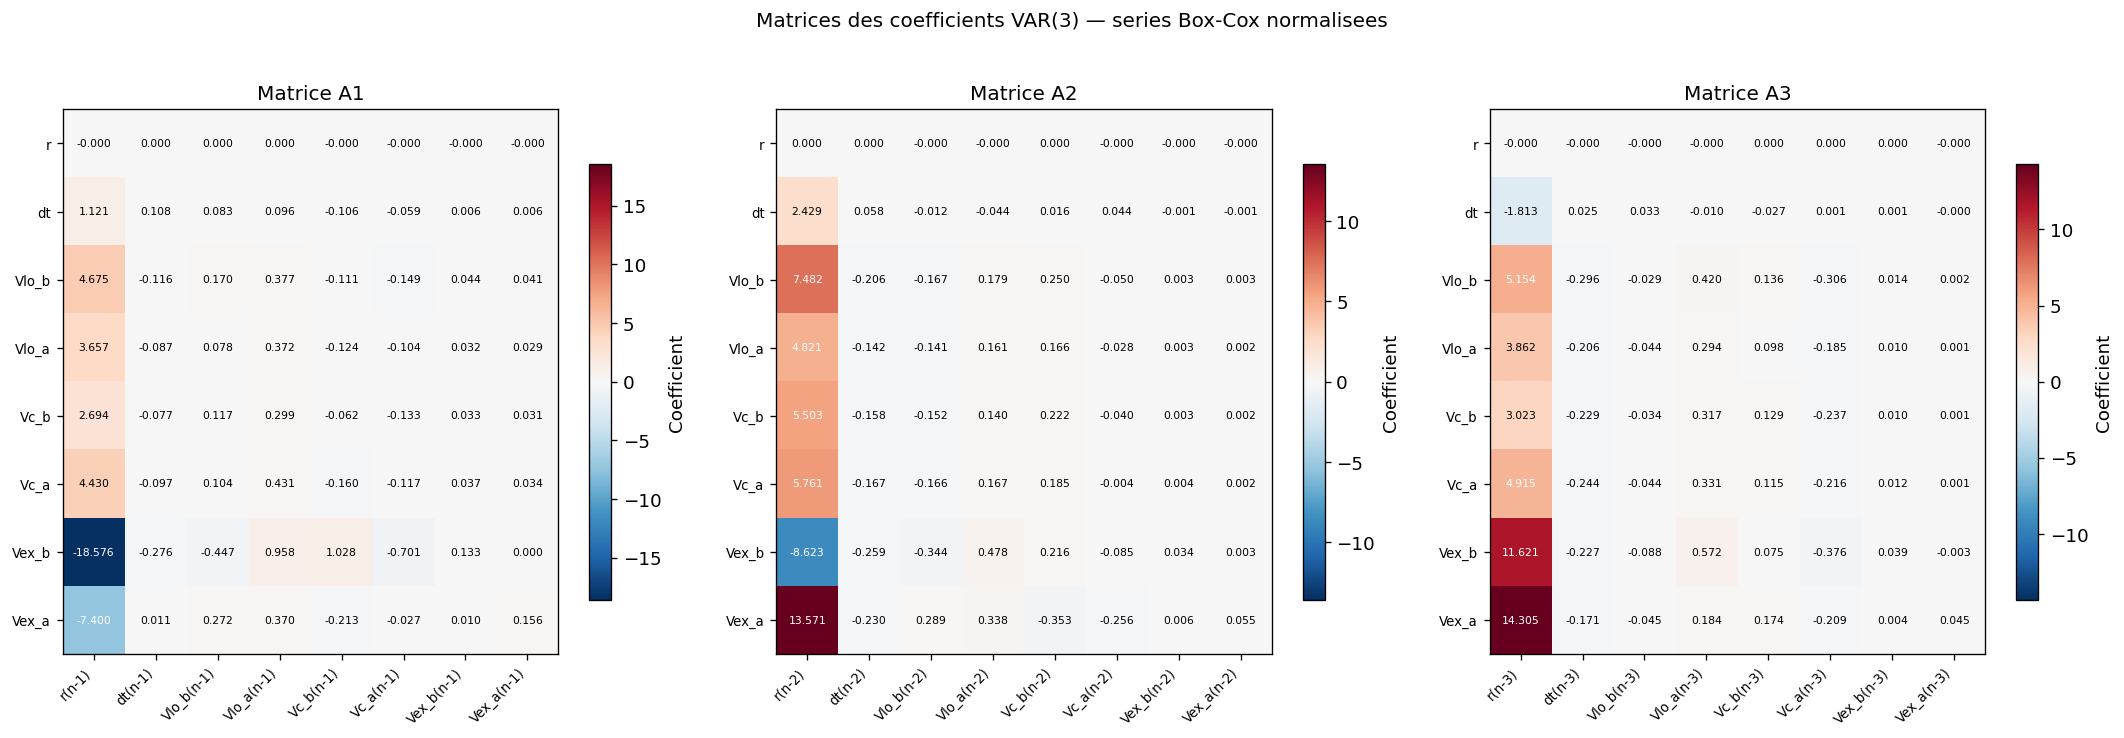

In [42]:
var_names_short = ['r', 'dt', 'Vlo_b', 'Vlo_a', 'Vc_b', 'Vc_a', 'Vex_b', 'Vex_a']

fig, axes = plt.subplots(1, BEST_LAG, figsize=(6 * BEST_LAG, 6))
if BEST_LAG == 1:
    axes = [axes]

for lag_i, ax in enumerate(axes):
    coef = result.coefs[lag_i]
    vmax = max(abs(coef.min()), abs(coef.max()))

    im = ax.imshow(coef, cmap='RdBu_r', aspect='auto', vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(len(var_names_short)))
    ax.set_yticks(range(len(var_names_short)))
    ax.set_xticklabels([f'{v}(n-{lag_i+1})' for v in var_names_short], rotation=45, ha='right', fontsize=8)
    ax.set_yticklabels(var_names_short, fontsize=8)
    ax.set_title(f'Matrice A{lag_i+1}', fontsize=12)

    for i in range(len(var_names_short)):
        for j in range(len(var_names_short)):
            val = coef[i, j]
            color = 'white' if abs(val) > 0.3 * vmax else 'black'
            ax.text(j, i, f'{val:.3f}', ha='center', va='center', fontsize=6.5, color=color)

    plt.colorbar(im, ax=ax, label='Coefficient', shrink=0.8)

fig.suptitle(f'Matrices des coefficients VAR({BEST_LAG}) — series Box-Cox normalisees', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

---
## Etape 8 — Diagnostics du VAR

On vérifie 3 choses (slide 8 du VAR 101) :
1. **Résidus → bruit blanc ?** — ACF des résidus doit être nulle
2. **Stabilité → valeurs propres dans le cercle unité ?**
3. **Autocorrélation → test de Ljung-Box**

In [ ]:
from statsmodels.stats.stattools import durbin_watson

# Stabilite : valeurs propres de la matrice compagnon
roots = result.roots
moduli = np.abs(roots)
stable = all(moduli < 1)

fig, ax = plt.subplots(figsize=(5, 5))
theta = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(theta), np.sin(theta), 'k-', linewidth=1, label='Cercle unite')

colors = ['tomato' if m >= 1 else 'steelblue' for m in moduli]
ax.scatter(roots.real, roots.imag, c=colors, s=60, zorder=3)

ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(0, color='gray', linewidth=0.5)
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
ax.set_aspect('equal')
ax.set_title(f'Stabilite VAR({BEST_LAG})\n{"✅ Stable" if stable else "❌ Instable — racines hors du cercle"}')

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='steelblue', label='Racines stables (|r| < 1)'),
    Patch(color='tomato',    label='Racines instables (|r| >= 1)'),
], fontsize=8)
plt.tight_layout()
plt.show()

print(f'Racines instables : {sorted(moduli[moduli >= 1], reverse=True).round(4) if not stable else "aucune"}')
print(f'Module max : {moduli.max():.4f}')
print(f'Module min : {moduli.min():.4f}')

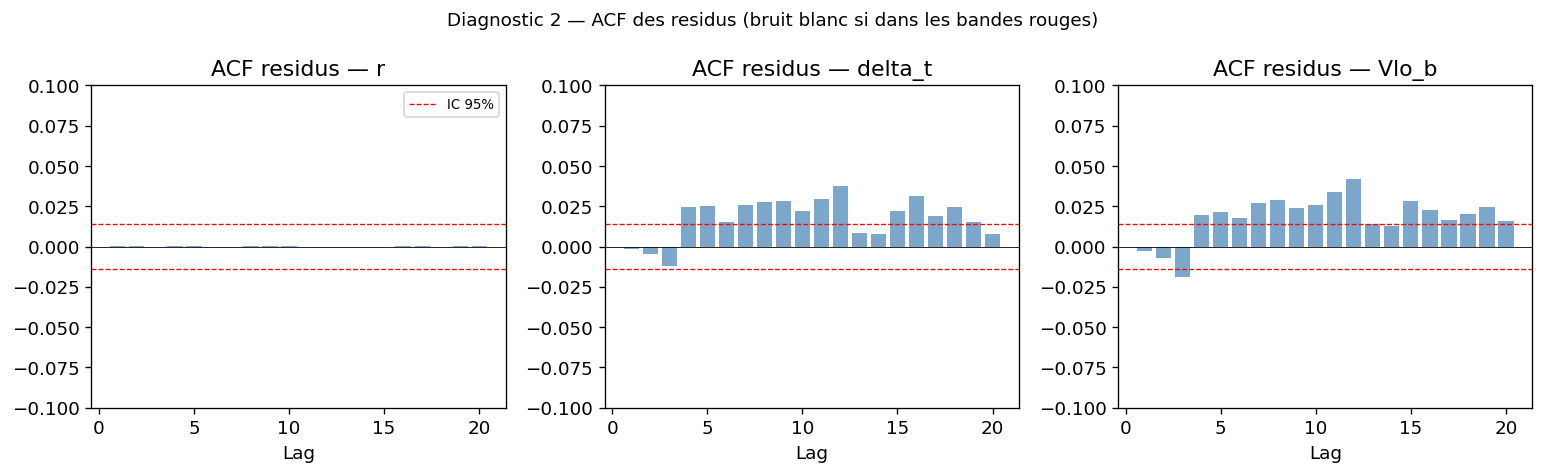

In [44]:
# ================================================================
# DIAGNOSTIC 2 : ACF des residus
# Si les residus sont un bruit blanc → ACF proche de 0 pour tous les lags
# On trace pour les 3 variables les plus importantes : r, delta_t, Vlo_b
# ================================================================
residuals = result.resid
focus_vars = ['r', 'delta_t', 'Vlo_b']
n_lags = 20

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ic_bound = 1.96 / np.sqrt(len(residuals))

for ax, var in zip(axes, focus_vars):
    col_idx = variables.index(var)
    resid = residuals.iloc[:, col_idx].values
    acf_vals = acf(resid, nlags=n_lags, fft=True)

    lags = np.arange(1, n_lags + 1)
    ax.bar(lags, acf_vals[1:], color='steelblue', alpha=0.7)
    ax.axhline( ic_bound, color='red', linestyle='--', linewidth=0.8, label='IC 95%')
    ax.axhline(-ic_bound, color='red', linestyle='--', linewidth=0.8)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_title(f'ACF residus — {var}')
    ax.set_xlabel('Lag')
    ax.set_ylim(-0.1, 0.1)
    if ax == axes[0]:
        ax.legend(fontsize=8)

fig.suptitle('Diagnostic 2 — ACF des residus (bruit blanc si dans les bandes rouges)', fontsize=11)
plt.tight_layout()
plt.show()

In [45]:
# ================================================================
# DIAGNOSTIC 3 : Test de Ljung-Box
# Test formel d autocorrelation sur les residus
# H0 : les residus sont un bruit blanc
# p-value > 0.05 → on ne rejette pas H0 → residus OK
# ================================================================
from statsmodels.stats.diagnostic import acorr_ljungbox

print(f'{"Variable":<12} {"Ljung-Box stat":>16} {"p-value":>10} {"Residus OK ?":>14}')
print('-' * 56)

for var in variables:
    col_idx = variables.index(var)
    resid = residuals.iloc[:, col_idx].values
    lb = acorr_ljungbox(resid, lags=[10], return_df=True)
    stat   = lb['lb_stat'].values[0]
    pvalue = lb['lb_pvalue'].values[0]
    ok = '✅ OUI' if pvalue > 0.05 else '❌ NON'
    print(f'{var:<12} {stat:>16.3f} {pvalue:>10.4f} {ok:>14}')

print()
print('Durbin-Watson (proche de 2 = pas d autocorr) :')
dw = durbin_watson(residuals.values)
for var, d in zip(variables, dw):
    print(f'  {var:<12} DW = {d:.3f}')

Variable       Ljung-Box stat    p-value   Residus OK ?
--------------------------------------------------------
r                       0.022     1.0000          ✅ OUI
delta_t                87.202     0.0000          ❌ NON
Vlo_b                  87.770     0.0000          ❌ NON
Vlo_a                  89.402     0.0000          ❌ NON
Vc_b                   91.933     0.0000          ❌ NON
Vc_a                   88.368     0.0000          ❌ NON
Vex_b                  74.943     0.0000          ❌ NON
Vex_a                  32.784     0.0003          ❌ NON

Durbin-Watson (proche de 2 = pas d autocorr) :
  r            DW = 2.000
  delta_t      DW = 2.003
  Vlo_b        DW = 2.006
  Vlo_a        DW = 2.006
  Vc_b         DW = 2.006
  Vc_a         DW = 2.006
  Vex_b        DW = 2.003
  Vex_a        DW = 2.003
